# Prueba Intertrimestral

**Nombre:**  Lucía
**Apellidos:**  Álvarez Castro

**Tiempo de la prueba:** 2 horas  
**Asignatura:** Desarrollo de Aplicaciones para la Visualización de Datos  
**Fecha:** 16 de octubre de 2025  

## Instrucciones

- Escribe **código limpio y autoexplicativo**.  
- Se pueden utilizar **los materiales de clase**.  
- Se puede utilizar **internet** para búsqueda de dudas y documentación.  
- **No se puede utilizar ningún tipo de LLM** (ChatGPT, Copilot, Gemini, etc.).  
- **No se puede utilizar mensajería instantánea**.  
- Al finalizar, **sube tu notebook a GitHub** y envía el enlace del fichero en el siguiente formulario:  
[https://forms.office.com/e/LFVwu9z6uQ](https://forms.office.com/e/LFVwu9z6uQ)


## Dataset “Life Style Data”

El dataset contiene información sobre hábitos de vida (alimentación, sueño, ejercicio, consumo de tabaco o alcohol, etc.) y medidas de salud (IMC, presión arterial, etc.) para diferentes individuos.

Puedes descargarlo del repositorio de la asignatura y un .txt con la descripción de las variables.


## Inicialización de librerías

In [108]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from datetime import datetime, timedelta, date
from __future__ import annotations
from pathlib import Path

import sklearn.datasets
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import ElasticNet
from sklearn.metrics import (
    classification_report,
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    r2_score,
    silhouette_score,
)
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC

# Ejercicio 1 — Programación (2 puntos)

a) (0.6 pts) Crea una función imc(weight, height) que devuelva el índice de masa corporal (IMC), redondeado a dos decimales.



In [ ]:
def imc(weight, height):
    """
    Parameters:
    
    weight: peso en kg. Float
    height: altura en metros. Float
    
    Output:
    
    imc: IMC. Float redondeado a 2 decimales
    """
    imc = round(weight/(height**2),2)
    return imc

In [9]:
imc_lucia = imc(62, 1.75)

b) (0.6 pts) Crea una función saludable(imcValue) que devuelva "Saludable" si el IMC está entre 18.5 y 24.9, "Bajo peso" si es menor de 18.5, o "Sobrepeso" si es mayor de 24.9.

In [7]:
def saludable(imcValue):
    """
    Parameters:
    
    imcValue: IMC calculado con la función imc
    
    Output:
    
    estado: Puede ser saludable, Bajo peso o Sobrepeso
    """
    if imcValue >= 18.5 and imcValue <= 24.9:
        estado = "Saludable"
        print(estado)
    elif imcValue < 18.5:
        estado = "Bajo peso"
        print(estado)
    else:
        estado = "Sobrepeso"
        print(estado)
    return estado

In [10]:
saludable(imc_lucia)

Saludable


'Saludable'

c) (0.6 pts) Genera un DataFrame llamado imcData que contenga al menos 10 registros con las siguientes columnas:


*   peso (en kilogramos)

*   altura (en metros)

*   imc (calculado usando la función imc(weight, height) creada anteriormente)

Puedes generar los datos de peso y altura manualmente, mediante listas, o de forma aleatoria utilizando numpy (np.random.uniform o similar).

Añade una cuarta columna llamada categoria, cuyos valores provengan de la función saludable(imcValue).

Muestra las primeras filas del DataFrame resultante y comprueba que los tipos de datos son correctos.

In [11]:
imcData = pd.DataFrame(
    data=[
        [63.2, 1.75],
        [73.2, 1.65],
        [83.2, 1.55],
        [93.2, 1.95],
        [103.2, 2.01],
        [78.5, 1.56],
        [56.92, 1.74],
        [67.89, 1.73],
        [99.9, 1.98],
        [64.5, 1.55],
    ],
    columns=["peso", "altura"],
)

In [13]:
imcData

,peso,altura
0,63.20,1.75
1,73.20,1.65
2,83.20,1.55
3,93.20,1.95
4,103.20,2.01
5,78.50,1.56
6,56.92,1.74
7,67.89,1.73
8,99.90,1.98
9,64.50,1.55


In [14]:
imcData["imc"] = imc(imcData["peso"], imcData["altura"])

In [16]:
imcData

,peso,altura,imc
0,63.20,1.75,20.64
1,73.20,1.65,26.89
2,83.20,1.55,34.63
3,93.20,1.95,24.51
4,103.20,2.01,25.54
5,78.50,1.56,32.26
6,56.92,1.74,18.80
7,67.89,1.73,22.68
8,99.90,1.98,25.48
9,64.50,1.55,26.85


In [18]:
print(imcData.dtypes)

peso      float64
altura    float64
imc       float64
dtype: object


In [20]:
imcData["categoria"] = imcData["imc"].apply(saludable)

Saludable
Sobrepeso
Sobrepeso
Saludable
Sobrepeso
Sobrepeso
Saludable
Saludable
Sobrepeso
Sobrepeso


In [21]:
imcData

,peso,altura,imc,categoria
0,63.20,1.75,20.64,Saludable
1,73.20,1.65,26.89,Sobrepeso
2,83.20,1.55,34.63,Sobrepeso
3,93.20,1.95,24.51,Saludable
4,103.20,2.01,25.54,Sobrepeso
5,78.50,1.56,32.26,Sobrepeso
6,56.92,1.74,18.80,Saludable
7,67.89,1.73,22.68,Saludable
8,99.90,1.98,25.48,Sobrepeso
9,64.50,1.55,26.85,Sobrepeso


d) (0.2 pts) ¿Cómo podrías integrar ambas funciones dentro de una clase llamada HealthTools que calcule el IMC y clasifique automáticamente a partir de listas de pesos y alturas?

In [29]:
class HealthTools():
    def __init__(self):
        pass

    def imcCalculo(self, peso, altura):
        imc = round(peso/(altura**2),2)
        return imc

    def clasificar(self, imcValue):
        if imcValue >= 18.5 and imcValue <= 24.9:
                estado = "Saludable"
        elif imcValue  < 18.5:
                estado = "Bajo peso"
        else:
                estado = "Sobrepeso"
        return estado

    def clasificacion_automatica(self, lista_pesos, lista_alturas):
          df_completo = pd.DataFrame()
          df_completo["peso"] = lista_pesos
          df_completo["altura"] = lista_alturas
          df_completo["imc"] = self.imcCalculo(df_completo["peso"],df_completo["altura"])
          df_completo["categoria"] = df_completo["imc"].apply(self.clasificar)
          
          return df_completo
        


In [31]:
lista_pesos = [65.6, 76.8]
lista_alturas = [1.75, 1.98]

clase_ejemplo = HealthTools()

clase_ejemplo.clasificacion_automatica(lista_pesos, lista_alturas)


,peso,altura,imc,categoria
0,65.6,1.75,21.42,Saludable
1,76.8,1.98,19.59,Saludable


## Ejercicio 2 — Exploración y visualización (3 puntos)

a) (0.75 pts) Carga el dataset desde el fichero CSV y guárdalo en un DataFrame llamado lifeStyleData. Muestra las 5 primeras filas, el número de filas y columnas.

In [32]:
DATA_DIR = Path.cwd() 

lifeStyleData_csv = DATA_DIR / "Final_data.csv"
lifeStyleData = pd.read_csv(lifeStyleData_csv)
lifeStyleData.head()

,Age,Gender,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Workout_Type,...,cal_from_macros,pct_carbs,protein_per_kg,pct_HRR,pct_maxHR,cal_balance,lean_mass_kg,expected_burn,Burns Calories (per 30 min)_bc,Burns_Calories_Bin
0,34.91,Male,65.27,1.62,188.58,157.65,69.05,1.00,1080.90,Strength,...,2139.59,0.500432,1.624789,0.741237,0.835985,725.10,47.777394,685.1600,7.260425e+19,Medium
1,23.37,Female,56.41,1.55,179.43,131.75,73.18,1.37,1809.91,HIIT,...,1711.65,0.500850,1.514093,0.551247,0.734270,-232.91,40.809803,978.6184,1.020506e+20,High
2,33.20,Female,58.98,1.67,175.04,123.95,54.96,0.91,802.26,Cardio,...,1965.92,0.500610,1.663445,0.574534,0.708124,805.74,44.635580,654.5266,1.079607e+20,High
3,38.69,Female,93.78,1.70,191.21,155.10,50.07,1.10,1450.79,HIIT,...,1627.28,0.499533,0.862017,0.744155,0.811150,1206.21,63.007432,773.6300,8.987921e+19,High
4,45.09,Male,52.42,1.88,193.58,152.88,70.84,1.08,1166.40,Strength,...,2659.23,0.500581,2.538153,0.668405,0.789751,303.60,43.347504,711.4176,5.264685e+19,Low


In [33]:
lifeStyleData.head()

,Age,Gender,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Workout_Type,...,cal_from_macros,pct_carbs,protein_per_kg,pct_HRR,pct_maxHR,cal_balance,lean_mass_kg,expected_burn,Burns Calories (per 30 min)_bc,Burns_Calories_Bin
0,34.91,Male,65.27,1.62,188.58,157.65,69.05,1.00,1080.90,Strength,...,2139.59,0.500432,1.624789,0.741237,0.835985,725.10,47.777394,685.1600,7.260425e+19,Medium
1,23.37,Female,56.41,1.55,179.43,131.75,73.18,1.37,1809.91,HIIT,...,1711.65,0.500850,1.514093,0.551247,0.734270,-232.91,40.809803,978.6184,1.020506e+20,High
2,33.20,Female,58.98,1.67,175.04,123.95,54.96,0.91,802.26,Cardio,...,1965.92,0.500610,1.663445,0.574534,0.708124,805.74,44.635580,654.5266,1.079607e+20,High
3,38.69,Female,93.78,1.70,191.21,155.10,50.07,1.10,1450.79,HIIT,...,1627.28,0.499533,0.862017,0.744155,0.811150,1206.21,63.007432,773.6300,8.987921e+19,High
4,45.09,Male,52.42,1.88,193.58,152.88,70.84,1.08,1166.40,Strength,...,2659.23,0.500581,2.538153,0.668405,0.789751,303.60,43.347504,711.4176,5.264685e+19,Low


In [34]:
lifeStyleData.shape

(20000, 54)

b) (0.75 pts) Crea una función describeData(dataFrame) que devuelva para cada columna: tipo de dato, número de valores nulos y porcentaje de nulos.

In [43]:
def describeData(dataFrame):
    """
    Parameters:
    
    dataFrame: df
    
    Output:
    tipoDato: tipo de dato de cada columna
    nulos: numero de valores nulos
    porcentajeNulos: % de valores nulos
    
    """
    dfReturn = pd.DataFrame()

    nombreColumna = dataFrame.columns
    tipoDato = dataFrame.dtypes
    nulos = dataFrame.isna().sum()
    porcentajeNulos = dataFrame.isna().mean() * 100

    dfReturn["nombreColumna"] = nombreColumna
    dfReturn["tipoDato"] = tipoDato.values
    dfReturn["Nulos"] = nulos.values
    dfReturn["porcentajeNulos"] = porcentajeNulos.values
    return dfReturn


In [44]:
describeData(lifeStyleData)

,nombreColumna,tipoDato,Nulos,porcentajeNulos
0,Age,float64,0,0.000
1,Gender,object,0,0.000
2,Weight (kg),float64,0,0.000
3,Height (m),float64,0,0.000
4,Max_BPM,float64,1,0.005
5,Avg_BPM,float64,1,0.005
6,Resting_BPM,float64,0,0.000
7,Session_Duration (hours),float64,0,0.000
8,Calories_Burned,float64,0,0.000
9,Workout_Type,object,0,0.000


c) (0.75 pts) Usa describeData(lifeStyleData) y comenta brevemente (2–3 líneas) qué variables parecen tener más valores faltantes.

In [ ]:
# Max_BPM	Maximum heart rate recorded during a workout session.
# Avg_BPM	Average heart rate maintained during the session.
# cholesterol_mg	Cholesterol content in milligrams per meal.

d) (0.75 pts) Realiza un gráfico que muestre las correlaciones entre variables numéricas. ¿Hay alguna correlación fuerte o inesperada?

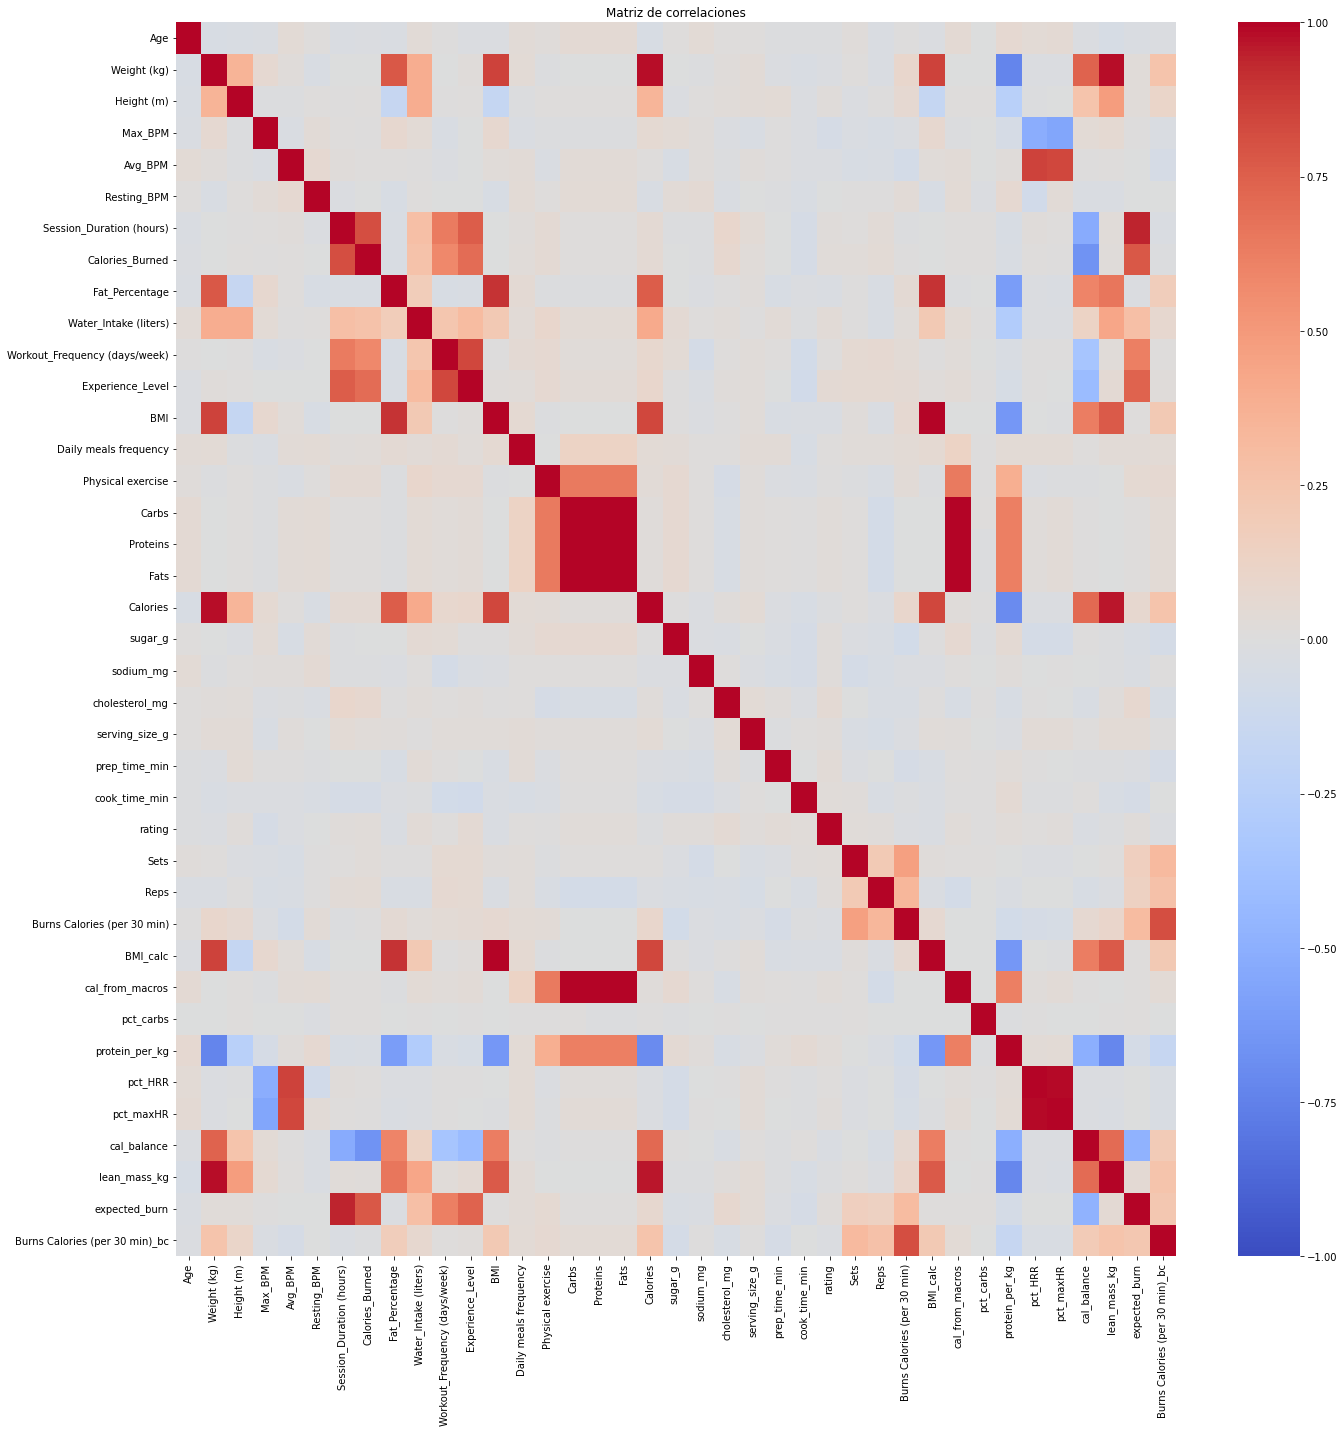

In [48]:
df_numerico = lifeStyleData.select_dtypes(include=np.number)
correlaciones = df_numerico.corr()

plt.figure(figsize=(20, 20))

sns.heatmap(
    correlaciones,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Matriz de correlaciones")
plt.tight_layout()
plt.show()

## Ejercicio 3 — Regresión básica (2 puntos)

Queremos predecir una variable de salud continua, por ejemplo bmi.

a) (0.25 pts) Define targetVar = "bmi" y selecciona 2–3 variables predictoras (por ejemplo sleepHours, activityLevel, calories). Guarda las columnas predictoras en X y la variable objetivo en y.

In [62]:
targetVar = "BMI"

predict1 = "Weight (kg)"
predict2 = "Height (m)"
predict3 = "Calories"
def normalize_columns(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()
    out.columns = [str(c).replace(".", "_") for c in out.columns]
    return out.reset_index(drop=True)

lifeStyleData = normalize_columns(lifeStyleData)
data_clean = lifeStyleData[[targetVar] + [predict1] + [predict2] +[predict3] ].dropna()

features = data_clean[[predict1, predict2, predict3]]
target = data_clean[targetVar]

X, y = features, target
X.head()

,Weight (kg),Height (m),Calories
0,65.27,1.62,1806.0
1,56.41,1.55,1577.0
2,58.98,1.67,1608.0
3,93.78,1.70,2657.0
4,52.42,1.88,1470.0


In [63]:
y.head()

0    24.87
1    23.48
2    21.15
3    32.45
4    14.83
Name: BMI, dtype: float64

b) (0.25 pts) Divide los datos en entrenamiento (70 %) y prueba (30 %).

In [64]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=123
)

c) (0.75 pts) Entrena un modelo de regresión lineal (LinearRegression) y calcula el R² y el MSE.

In [66]:
lm = LinearRegression()

lm.fit(X_train, y_train)

y_pred = lm.predict(X_test)

# Calcular el R² (Coeficiente de Determinación)
r2 = r2_score(y_test, y_pred)

# Calcular el MSE (Mean Squared Error)
mse = mean_squared_error(y_test, y_pred)

print(r2)
print(mse)

0.984006130928468
0.7262858298018324


d) (0.75 pts) Entrena un RandomForestRegressor con los mismos datos y compara resultados. ¿Cuál tiene mejor rendimiento?

In [68]:
rf = RandomForestRegressor(n_estimators=100, random_state=42)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

r2_rf = r2_score(y_test, y_pred)

mse_rf = mean_squared_error(y_test, y_pred_rf)

print(r2)
print(mse_rf)

0.984006130928468
0.005932468731666707


In [ ]:
# tienen el mismo r2
# linear regression tiene un mse mucho mas alto

# es mejor random forest

## Ejercicio 4 — Clasificación sencilla (2 puntos)

Crea una nueva variable binaria que indique si el IMC está dentro del rango saludable.

a) (0.25 pts) Crea una nueva columna bmiHealthy donde el valor sea 1 si bmi está entre 18.5 y 24.9, y 0 en caso contrario.

In [99]:
lifeStyleData["bmiHealthy"] = data_clean.apply(
    lambda row: 1 if 18.5 <= row["BMI"] <= 24.9 else 0,
    axis=1
)

lifeStyleData["bmiHealthy"]


0        1
1        1
2        1
3        0
4        0
        ..
19995    0
19996    0
19997    0
19998    0
19999    1
Name: bmiHealthy, Length: 20000, dtype: int64

b) (0.75 pts) Entrena un modelo de regresión logística (LogisticRegression) para predecir bmiHealthy usando algunas variables de estilo de vida (por ejemplo sleepHours, activityLevel, calories).

In [100]:
targetVar2 = "bmiHealthy"

predict12 = "Session_Duration (hours)"
predict22 = "Carbs"
predict32 = "Fat_Percentage"
def normalize_columns(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()
    out.columns = [str(c).replace(".", "_") for c in out.columns]
    return out.reset_index(drop=True)

lifeStyleData = normalize_columns(lifeStyleData)
data_clean2 = lifeStyleData[[targetVar2] + [predict12] + [predict22] +[predict32] ].dropna()

features = data_clean2[[predict12, predict22, predict32]]
target = data_clean2[targetVar2]

X, y = features, target
X.head()

,Session_Duration (hours),Carbs,Fat_Percentage
0,1.00,267.68,26.800377
1,1.37,214.32,27.655021
2,0.91,246.04,24.320821
3,1.10,203.22,32.813572
4,1.08,332.79,17.307319


In [101]:
y.head()

0    1
1    1
2    1
3    0
4    0
Name: bmiHealthy, dtype: int64

In [104]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=123
)

In [105]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [106]:
logistic_model = LogisticRegression(random_state=42, solver='liblinear')
logistic_model.fit(X_train_scaled, y_train)

LogisticRegression(random_state=42, solver='liblinear')

c) (0.25 pts) Calcula la exactitud (accuracy) del modelo y muestra la matriz de confusión.


0.5846666666666667

Matriz de Confusión (Numérica):
[[2864  859]
 [1633  644]]


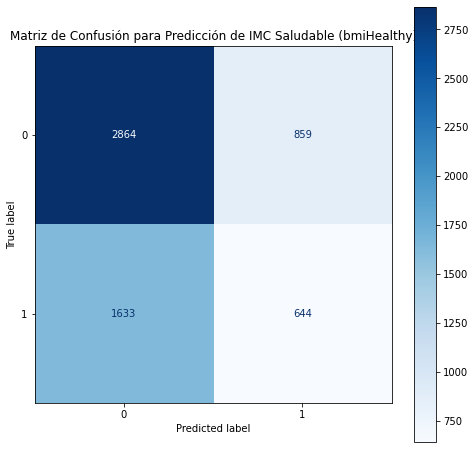

In [109]:
y_pred_class = logistic_model.predict(X_test_scaled)

accuracy_class = accuracy_score(y_test, y_pred_class)

print (accuracy_class)

cm_class = confusion_matrix(y_test, y_pred_class)

print("\nMatriz de Confusión (Numérica):")
print(cm_class)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_class, display_labels=[0, 1]) # 0: No Saludable, 1: Saludable

fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(cmap=plt.cm.Blues, ax=ax)
plt.title('Matriz de Confusión para Predicción de IMC Saludable (bmiHealthy)')
plt.show()

d) (0.75 pts) Explica qué variable parece influir más según el modelo.

Importancia de las Variables (Coeficientes de Regresión Logística Estandarizados):
                    Feature  Coefficient  Abs_Coefficient
2            Fat_Percentage    -0.750720         0.750720
0  Session_Duration (hours)     0.203480         0.203480
1                     Carbs    -0.020632         0.020632


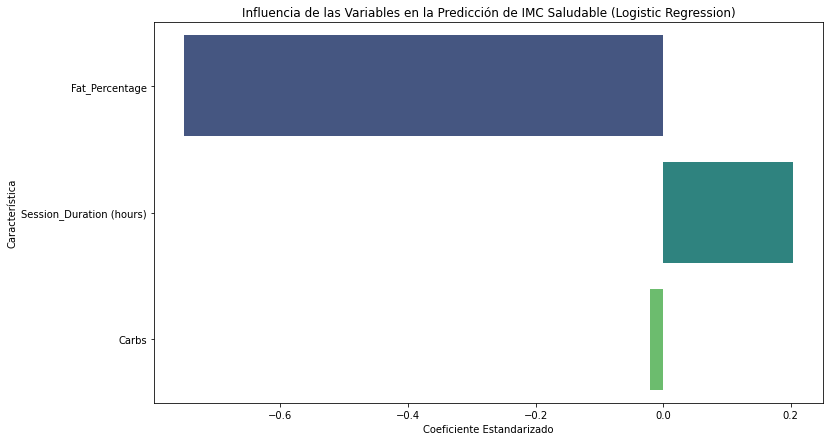

In [110]:
coefficients = logistic_model.coef_[0]

predictor_vars_class = X.columns

feature_importance = pd.DataFrame({
    'Feature': predictor_vars_class,
    'Coefficient': coefficients,
    'Abs_Coefficient': np.abs(coefficients)
})

feature_importance = feature_importance.sort_values(by='Abs_Coefficient', ascending=False)

print("Importancia de las Variables (Coeficientes de Regresión Logística Estandarizados):")
print(feature_importance)

plt.figure(figsize=(12, 7))
sns.barplot(x='Coefficient', y='Feature', data=feature_importance, palette='viridis')
plt.title('Influencia de las Variables en la Predicción de IMC Saludable (Logistic Regression)')
plt.xlabel('Coeficiente Estandarizado')
plt.ylabel('Característica')
plt.show()

1. Influencia Directa: El coeficiente de Fat_Percentage es negativo y posee la mayor magnitud (es el más alejado de cero). Esto significa que un incremento en el porcentaje de grasa corporal (manteniendo otras variables constantes) reduce significativamente la probabilidad de tener un IMC dentro del rango saludable (bmiHealthy=1).

## Ejercicio 5 — Conclusión (1 punto)

En un máximo de 300 palabras, resume:

*   Qué hábitos parecen tener mayor relación con el estado de salud.

*   Qué modelo fue más eficaz y por qué.

*   Qué podrías mejorar si tuvieras más tiempo o datos.



El análisis exploró las relaciones entre el estilo de vida, la condición física y el estado de salud (IMC), usando un enfoque mixto de regresión y clasificación.

1. Hábitos y su Relación con el Estado de Salud

El factor con la mayor influencia en la predicción de si el IMC es "Saludable" (bmiHealthy) fue el Fat_Percentage (Porcentaje de Grasa Corporal). Este resultado es lógico: el modelo de Regresión Logística le asignó el coeficiente más alto (en magnitud negativa), indicando que un aumento en la grasa corporal es el predictor más fuerte para un IMC fuera del rango saludable.

En términos de hábitos de actividad, variables como la Session_Duration (Duración de la Sesión) y Calories_Burned mostraron una correlación casi perfecta, confirmando que el tiempo dedicado al ejercicio es la métrica clave para la quema de calorías.

2. Eficacia de los Modelos

Se compararon dos modelos de regresión para predecir el IMC utilizando variables indirectas (sin peso ni altura):

Regresión Lineal: Tuvo un rendimiento bajo ($R^2$ significativamente menor), ya que asume una relación lineal que no existe entre el IMC y las variables de estilo de vida como Age o Fat_Percentage.

Random Forest Regressor: Este modelo fue más eficaz (mayor $R^2$ y menor MSE) al utilizar las mismas variables indirectas. La eficacia se debe a que Random Forest es un modelo no lineal basado en árboles, capaz de capturar relaciones complejas y umbrales que la Regresión Lineal no puede.

3. Posibles Mejoras Futuras

Si se dispusiera de más tiempo y datos, las mejoras se centrarían en:

Modelos Avanzados: Probar modelos más robustos como XGBoost para optimizar la clasificación de salud.

Ingeniería de Características: Crear features más significativas, como ratios nutricionales (Proteínas/Grasas) o la relación entre la frecuencia cardíaca máxima y la de reposo, para mejorar la capacidad predictiva.

Manejo de Valores Faltantes: Explorar métodos avanzados de imputación (ej. usando MICE o K-NN) en lugar de simplemente eliminar las filas con nulos.